## Step 1: Load multi-season match data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

clean_matches = pd.read_csv("../data/processed/clean_matches_multi_season.csv", parse_dates=["utcDate"], dtype={"season": str})

home_goals = clean_matches.groupby("home_team_name")["home_goals"].sum()
away_goals = clean_matches.groupby("away_team_name")["away_goals"].sum()
total_goals = (home_goals.add(away_goals, fill_value=0)).sort_values(ascending=False)

home_conceded = clean_matches.groupby("home_team_name")["away_goals"].sum()
away_conceded = clean_matches.groupby("away_team_name")["home_goals"].sum()
total_conceded = (home_conceded.add(away_conceded, fill_value=0)).sort_values()

## Top 10 goal scorers (across all seasons)

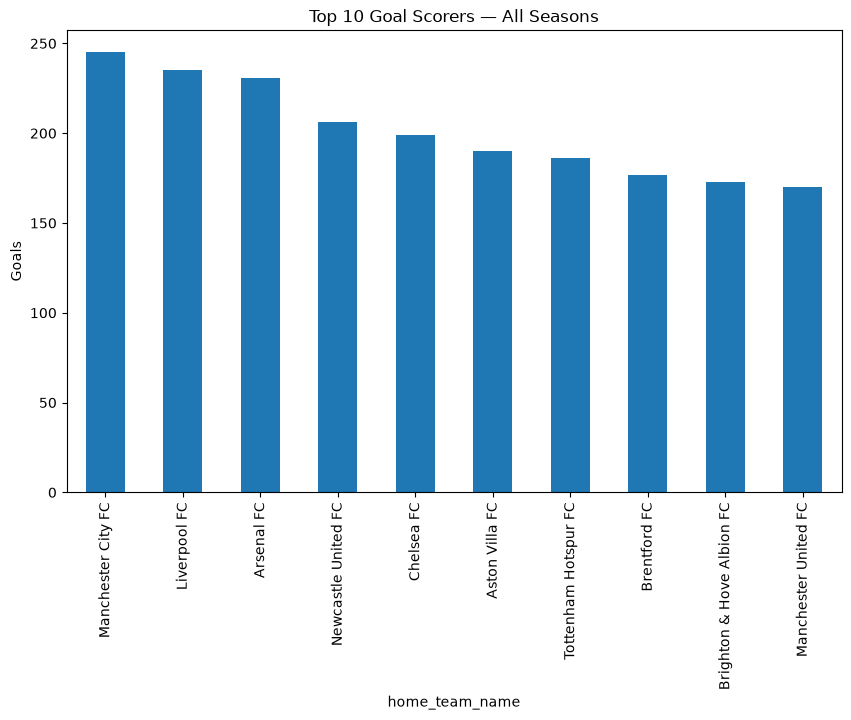

In [2]:
plt.figure(figsize=(10, 6))
total_goals.head(10).plot(kind="bar")
plt.title("Top 10 Goal Scorers — All Seasons")
plt.ylabel("Goals")
plt.show()

## Best defensive records (fewest goals conceded, across all seasons)

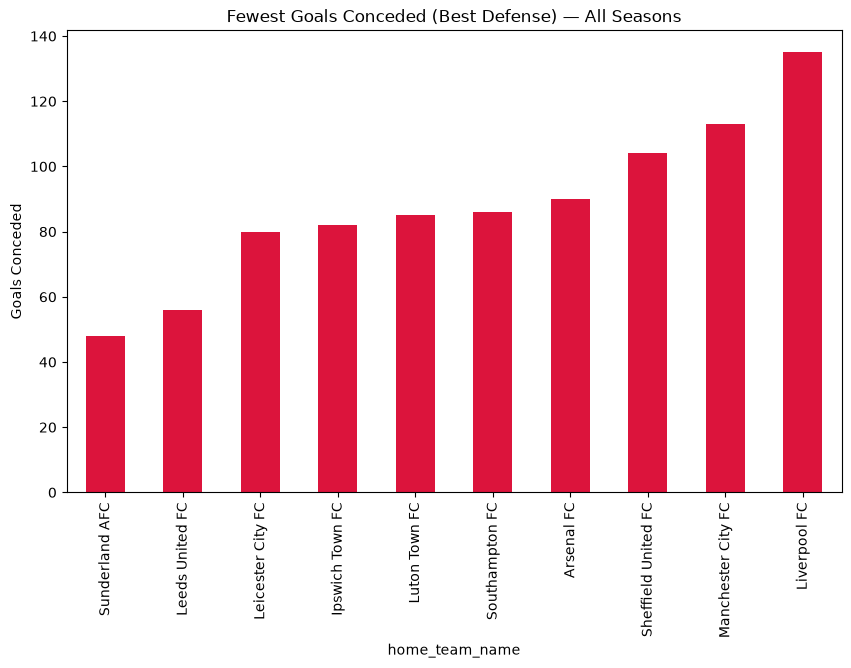

In [3]:
plt.figure(figsize=(10, 6))
total_conceded.head(10).plot(kind="bar", color="crimson")
plt.title("Fewest Goals Conceded (Best Defense) — All Seasons")
plt.ylabel("Goals Conceded")
plt.show()

## Step 2: Add month and total-match-goals columns

In [4]:
clean_matches["month"] = clean_matches["utcDate"].dt.month_name()
clean_matches["total_match_goals"] = clean_matches["home_goals"] + clean_matches["away_goals"]

## Total goals by month (across all seasons)
Reordered to follow the football season calendar (August → May) rather than alphabetical order.

In [5]:
season_month_order = ["August", "September", "October", "November", "December",
                       "January", "February", "March", "April", "May"]

goals_by_month = clean_matches.groupby("month")["total_match_goals"].sum().reindex(season_month_order)
goals_by_month

month
August       239
September    294
October      272
November     327
December     559
January      330
February     403
March        233
April        406
May          343
Name: total_match_goals, dtype: int64

## Goals by month — visualized

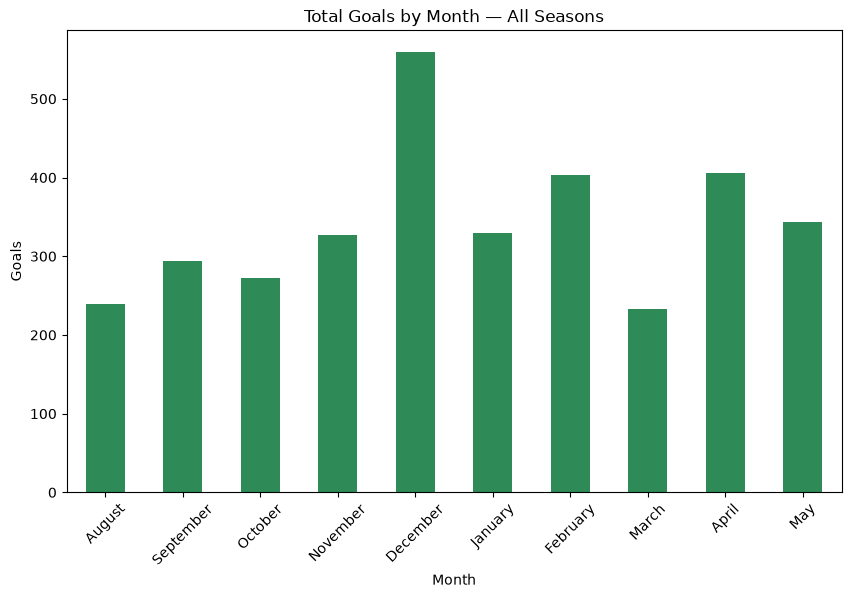

In [6]:
plt.figure(figsize=(10, 6))
goals_by_month.plot(kind="bar", color="seagreen")
plt.title("Total Goals by Month — All Seasons")
plt.ylabel("Goals")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.show()

## Average goals per match, by month

In [7]:
matches_by_month = clean_matches.groupby("month")["id"].count().reindex(season_month_order)
goals_per_match = (goals_by_month / matches_by_month).round(2)
goals_per_match

month
August       2.78
September    2.91
October      2.92
November     3.08
December     3.04
January      3.00
February     3.20
March        2.74
April        3.05
May          2.96
dtype: float64

## Step 3: Compute each team's final standing, per season
Derived directly from match results (points, then goal difference tie-break) rather than a separate standings API pull — keeps this notebook self-contained and consistent across all 3 seasons.

In [8]:
home_pts = clean_matches[["season", "home_team_name", "home_goals", "away_goals", "winner"]].copy()
home_pts.columns = ["season", "team", "goals_for", "goals_against", "winner"]
home_pts["points"] = home_pts["winner"].map({"HOME_TEAM": 3, "DRAW": 1, "AWAY_TEAM": 0})

away_pts = clean_matches[["season", "away_team_name", "away_goals", "home_goals", "winner"]].copy()
away_pts.columns = ["season", "team", "goals_for", "goals_against", "winner"]
away_pts["points"] = away_pts["winner"].map({"AWAY_TEAM": 3, "DRAW": 1, "HOME_TEAM": 0})

season_team_points = pd.concat([home_pts, away_pts])
season_team_points["goal_diff"] = season_team_points["goals_for"] - season_team_points["goals_against"]

standings = (
    season_team_points.groupby(["season", "team"])
    .agg(points=("points", "sum"), goal_diff=("goal_diff", "sum"))
    .reset_index()
)

standings = standings.sort_values(["season", "points", "goal_diff"], ascending=[True, False, False])
standings["position"] = standings.groupby("season").cumcount() + 1

standings.head(10)

,season,team,points,goal_diff,position
12,2023,Manchester City FC,91,62,1
1,2023,Arsenal FC,89,62,2
10,2023,Liverpool FC,82,45,3
2,2023,Aston Villa FC,68,15,4
17,2023,Tottenham Hotspur FC,66,13,5
6,2023,Chelsea FC,63,14,6
14,2023,Newcastle United FC,60,23,7
13,2023,Manchester United FC,60,-1,8
18,2023,West Ham United FC,52,-14,9
7,2023,Crystal Palace FC,49,-1,10


## Step 4: Attach each team's position for THAT season onto every match
Unlike a single static snapshot, this correctly reflects that a team's rank changes from season to season.

In [9]:
position_lookup = standings.set_index(["season", "team"])["position"]

clean_matches["home_position"] = clean_matches.apply(
    lambda r: position_lookup.get((r["season"], r["home_team_name"])), axis=1
)
clean_matches["away_position"] = clean_matches.apply(
    lambda r: position_lookup.get((r["season"], r["away_team_name"])), axis=1
)

clean_matches[["season", "home_team_name", "home_position", "away_team_name", "away_position", "winner"]].head()

,season,home_team_name,home_position,away_team_name,away_position,winner
0,2023,Burnley FC,19,Manchester City FC,1,AWAY_TEAM
1,2023,Arsenal FC,2,Nottingham Forest FC,17,HOME_TEAM
2,2023,AFC Bournemouth,13,West Ham United FC,9,DRAW
3,2023,Brighton & Hove Albion FC,11,Luton Town FC,18,HOME_TEAM
4,2023,Everton FC,12,Fulham FC,14,AWAY_TEAM


## Biggest upsets (across all seasons, using each match's own season's standings)

In [10]:
def get_upset_magnitude(row):
    if row["winner"] == "HOME_TEAM":
        winner_pos, loser_pos = row["home_position"], row["away_position"]
    elif row["winner"] == "AWAY_TEAM":
        winner_pos, loser_pos = row["away_position"], row["home_position"]
    else:
        return None  # draws aren't upsets in this definition

    if winner_pos > loser_pos:
        return winner_pos - loser_pos
    else:
        return 0

clean_matches["upset_magnitude"] = clean_matches.apply(get_upset_magnitude, axis=1)

biggest_upsets = clean_matches[clean_matches["upset_magnitude"] > 0].sort_values(
    "upset_magnitude", ascending=False
)

biggest_upsets[[
    "season", "utcDate", "home_team_name", "home_position", "away_team_name", "away_position",
    "home_goals", "away_goals", "winner", "upset_magnitude"
]].head(10)

,season,utcDate,home_team_name,home_position,away_team_name,away_position,home_goals,away_goals,winner,upset_magnitude
1031,2025,2026-02-27 20:00:00+00:00,Wolverhampton Wanderers FC,20,Aston Villa FC,4,2,0,HOME_TEAM,16.0
771,2025,2025-08-23 11:30:00+00:00,Manchester City FC,2,Tottenham Hotspur FC,17,0,2,AWAY_TEAM,15.0
1044,2025,2026-03-03 20:15:00+00:00,Wolverhampton Wanderers FC,20,Liverpool FC,5,2,1,HOME_TEAM,15.0
566,2024,2024-12-30 19:45:00+00:00,Ipswich Town FC,19,Chelsea FC,4,2,0,HOME_TEAM,15.0
65,2023,2023-09-30 14:00:00+00:00,Wolverhampton Wanderers FC,15,Manchester City FC,1,2,1,HOME_TEAM,14.0
496,2024,2024-11-23 17:30:00+00:00,Manchester City FC,3,Tottenham Hotspur FC,17,0,4,AWAY_TEAM,14.0
107,2023,2023-11-05 14:00:00+00:00,Nottingham Forest FC,17,Aston Villa FC,4,2,0,HOME_TEAM,13.0
1106,2025,2026-05-03 18:00:00+00:00,Aston Villa FC,4,Tottenham Hotspur FC,17,1,2,AWAY_TEAM,13.0
774,2025,2025-08-23 14:00:00+00:00,Burnley FC,19,Sunderland AFC,7,2,0,HOME_TEAM,12.0
535,2024,2024-12-15 16:30:00+00:00,Manchester City FC,3,Manchester United FC,15,1,2,AWAY_TEAM,12.0


> **Note:** "Upset" is judged using each team's *final* season position, not their standing at the time of the match — so an early-season result can only be judged an upset in hindsight, once that season's table is decided.